In [1]:
import pandas as pd
from langchain.text_splitter import RecursiveCharacterTextSplitter
import os
import getpass
import warnings
warnings.filterwarnings("ignore")
if not os.environ.get("NVIDIA_API_KEY", "").startswith("nvapi-"):
    nvapi_key = getpass.getpass("Enter your NVIDIA API key: ")
    assert nvapi_key.startswith("nvapi-"), f"{nvapi_key[:5]}... is not a valid key"
    os.environ["NVIDIA_API_KEY"] = nvapi_key


In [2]:
path = '/home/g05_u03/sgp_bootcamp_material/sgp_bootcamp_material/rsm-nvidia-hackathon/data/raw/raw_scapred_dataset_sample.csv'
df = pd.read_csv(path)

In [3]:
prompt = """
## Instructions
1. **Paragraph Analysis**: For each paragraph (or row of text), analyze the content and extract key information relevant to the context. Focus on identifying the most critical details and ensuring that the extraction retains the original meaning and emphasis without rephrasing or additional interpretation.
2. **Key Information Selection**: Identify the main elements within the paragraph, focusing on actionable, relevant, and meaningful details about how the Australian Government can mitigate any potential risks of AI and support safe and responsible AI practices. Disregard extraneous or unrelated content. Ensure clarity and precision in the selected information.
3. **Theme Extraction**: From the selected key information, extract overarching themes or topics that encapsulate the central idea of the paragraph. Use a sophisticated understanding of the text to discern nuanced themes, ensuring each theme represents a distinct aspect of the content.
4. **JSON Output**:  
- ALWAYS output a VALID JSON array of objects
- DO NOT ADD ANY additional text, labels, or introductory phrases to the provided JSON output format, e.g. Based on the provided context, here is the JSON output:
- EACH object MUST have exactly 3 keys: "id_number", "key_lines", "key_themes" and DO NOT ADD ANY additional text, labels, or introductory phrases outside of the desired output
- Ensure number of key_lines output match the number of key_themes and the output format is consistent across each iterations

Input Format Example:
```json
[
    {
        "id_number": "1",
        "key_lines": "Example text about AI regulation",
        "key_themes": "Regulatory framework development"  *without the brackets, use ',' as delimit
    }
]

5. Provide JSON Output
"""


In [4]:
from openai import OpenAI
import json
import re

def llm(chunk):
    client = OpenAI(
    base_url = "https://integrate.api.nvidia.com/v1",
    api_key = "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"
    )

    # Context definition
    LLM_Context = chunk
    
    # Instructions for LLM
    Instructions = prompt
    
    LLM_INPUT = f'''
    ## Context: {LLM_Context}
    
    ## Instructions: {Instructions}
    '''

    completion = client.chat.completions.create(
    model="mistralai/mixtral-8x7b-instruct-v0.1",
    messages=[{"role":"user","content":LLM_INPUT}],
    temperature=0,
    top_p=0.7,
    max_tokens=25000,
    stream=True
    )
    
    processed_output = ""

    for chunk in completion:
        if chunk.choices[0].delta.content is not None:
            processed_output += chunk.choices[0].delta.content
            processed_output = re.sub("\s+", " ", processed_output).strip()
    return processed_output


In [5]:
results = []  # To store results for all rows

for _, row in df.iterrows():
    context = row['Raw_Scraped_Text']  # Get the context text from the DataFram

    try:
        response = llm(context)  # Call the function with the context
        print(f'context: {row} -- response: {response}')
        data = json.loads(response)
        results.append(data)
    except Exception as e:
        raise e


context: ID                                                                  1
URL_MAIN            https://consult.industry.gov.au/ai-mandatory-g...
Owner                                                   CPA Australia
Raw_Scraped_Text     \n \nAI Consultation Team  \nIndustry House \...
Document_Name       Submission_Mandatory_Guardrails_for_AI_October...
File_Name           Submission_Mandatory_Guardrails_for_AI_October...
Document_Type                                                     pdf
Name: 0, dtype: object -- response: [ { "id_number": "1", "key_lines": "CPA Australia represents over173,000 accounting and finance professionals and supports the development of regulatory options for safe and responsible AI use in high-risk situations. A well-designed, clear, and proportionate regulatory regime is appropriate, targeting likely high-risk AI applications.", "key_themes": "Regulatory framework development, High-risk AI applications" }, { "id_number": "2", "key_lines": "The governme

In [6]:
processed_df = pd.DataFrame(columns = ['doc_id','id_number', 'key_lines', 'key_themes']) 
doc_id = 1
for result in results:
    tmp_df = pd.DataFrame(result)
    tmp_df.insert(0, 'doc_id', doc_id)
    processed_df = pd.concat([processed_df,tmp_df],ignore_index=True)
    doc_id += 1
      

In [7]:
# Function to ensure `key_themes` is not in list format
def convert_key_themes(value):
    if isinstance(value, list):  # Check if the value is a list
        return ', '.join(value)  # Join list items into a string
    return value  # If it's not a list, return as is

# Apply the function to the 'key_themes' column
processed_df['key_themes'] = processed_df['key_themes'].apply(convert_key_themes)

# View the modified DataFrame
print(processed_df[['doc_id', 'key_themes']])

   doc_id                                         key_themes
0       1  Regulatory framework development, High-risk AI...
1       1  Consultation, Definitions, High-risk AI applic...
2       1  Principles, High-risk AI applications, Health ...
3       1  Graphical representation, High-risk AI applica...
4       1      Mandatory guardrails, GPAI, Regulatory regime
5       1  Oversight, Taskforce, Guardrails, Independent ...
6       1  Guidance, Tools, Education, SMEs, Regulatory r...
7       1  Legislative options, Guardrails, Regulatory fr...
8       1       Policy development, Responsibility, Treasury
9       2  Proactive government role, AI development, AI ...
10      2   Economic benefits, Quality of life, AI potential
11      2  National AI ethics framework, Transparency, Fa...
12      2   Privacy, Security, Compliance with existing laws
13      2  Government investment, Collaboration, AI resea...
14      2  Augment human capabilities, Job preservation, ...
15      2      National 

In [8]:
processed_df

,doc_id,id_number,key_lines,key_themes
0,1,1,"CPA Australia represents over173,000 accountin...","Regulatory framework development, High-risk AI..."
1,1,2,The government should issue a further consulta...,"Consultation, Definitions, High-risk AI applic..."
2,1,3,The government should tighten the wording of t...,"Principles, High-risk AI applications, Health ..."
3,1,4,The government should include a graphical repr...,"Graphical representation, High-risk AI applica..."
4,1,5,The mandatory guardrails should only apply to ...,"Mandatory guardrails, GPAI, Regulatory regime"
5,1,6,The Proposals Paper is unclear on how the mand...,"Oversight, Taskforce, Guardrails, Independent ..."
6,1,7,"The government should develop simple guidance,...","Guidance, Tools, Education, SMEs, Regulatory r..."
7,1,8,CPA Australia does not have a set position on ...,"Legislative options, Guardrails, Regulatory fr..."
8,1,9,The government should move responsibility for ...,"Policy development, Responsibility, Treasury"
9,2,1,The Australian Government is urged to take a p...,"Proactive government role, AI development, AI ..."


In [9]:
# Initialize an empty list to store the processed rows
rows_to_keep = []

# Start with an empty string to accumulate content for the same doc_id
accumulated_content = ""
current_doc_id = None

# Iterate through each row
for i in range(len(processed_df)):
    current_row = processed_df.iloc[i]
    
    if current_row['doc_id'] == current_doc_id:
        # If doc_id is the same as the previous row, concatenate the content
        accumulated_content += "," + current_row['key_themes']
    else:
        # If doc_id is different, append the accumulated content to the rows_to_keep list
        if current_doc_id is not None:
            rows_to_keep.append({'doc_id': current_doc_id, 'key_themes': accumulated_content})
        
        # Start a new accumulation for the new doc_id
        accumulated_content = current_row['key_themes']
        current_doc_id = current_row['doc_id']

# Append the last accumulated content
if current_doc_id is not None:
    rows_to_keep.append({'doc_id': current_doc_id, 'key_themes': accumulated_content})

# Convert the result back to aa DataFrame
final_df = pd.DataFrame(rows_to_keep)

final_df


,doc_id,key_themes
0,1,"Regulatory framework development, High-risk AI..."
1,2,"Proactive government role, AI development, AI ..."
2,3,"Organization background,Government commitment ..."
3,4,"AI regulation, eSafety Commissioner, submissio..."


In [10]:
def get_unique_themes(themes):
    theme_list = themes.split(',')  # Split by commas
    unique_themes = set(theme.strip() for theme in theme_list)  # Remove extra spaces and get unique themes
    return ', '.join(unique_themes)  # Join them back into a single string

# Apply the function to the key_themes column
final_df['key_themes'] = final_df['key_themes'].apply(get_unique_themes)

final_df

,doc_id,key_themes
0,1,"Guidance, Consultation, Health care, GPAI, Hig..."
1,2,"AI use, Collaboration, Fairness, Augment human..."
2,3,"Government commitment to AI regulation, ISO de..."
3,4,"benefit promotion, coordinated approach, eSafe..."


In [11]:
final_df['key_themes'] = final_df['key_themes'].apply(lambda x: [x] if not isinstance(x, list) else x)


In [16]:
from openai import OpenAI
client = OpenAI(
  api_key="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",
  base_url="https://integrate.api.nvidia.com/v1"
)


embedding_outputs = []
per_theme = []
n_id = []
sub_id = []
for _,rows in final_df.iterrows():
    themes = rows['key_themes']
    id = rows['doc_id']
    for theme in themes:
        tmp_cnt = 1
        for each_theme in theme.split(', '):
            response = client.embeddings.create(
            input=[each_theme],
            model="nvidia/llama-3.2-nv-embedqa-1b-v1",
            encoding_format="float",
            extra_body={"input_type": "passage", "truncate": "NONE"}
    )
            embedding_outputs.append(response.data[0].embedding)        
            per_theme.append(each_theme)   
            n_id.append(id)  
            sub_id.append(tmp_cnt) 
            tmp_cnt+=1

In [17]:
actual_output = pd.DataFrame({'embedding':embedding_outputs, 'theme':per_theme,'id':n_id, 'sub_id':sub_id})

In [18]:
actual_output

,embedding,theme,id,sub_id
0,"[-0.0237274169921875, 0.002529144287109375, 0....",Guidance,1,1
1,"[-0.020904541015625, -0.007350921630859375, 0....",Consultation,1,2
2,"[-0.02001953125, -0.006420135498046875, 0.0337...",Health care,1,3
3,"[-0.01556396484375, -0.0217132568359375, 0.006...",GPAI,1,4
4,"[-0.0099639892578125, -0.01346588134765625, 0....",High-risk AI applications,1,5
...,...,...,...,...
69,"[-0.012054443359375, 0.0012674331665039062, 0....",harm mitigation,4,15
70,"[-0.019989013671875, -0.00525665283203125, 0.0...",AI purposes,4,16
71,"[-0.01233673095703125, -0.01306915283203125, 0...",DP-REG,4,17
72,"[-0.0220947265625, 0.0095977783203125, 0.02505...",online safety,4,18


In [24]:
pip install umap-learn pandas numpy

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.8/88.8 KB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.9/56.9 KB 11.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 11.0 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.9/43.9 MB 6.8 MB/s eta 0:00:00:00:0100:01
Note: you may need to restart the kernel to use updated packages.


In [29]:
import umap.umap_ as umap

In [33]:
umap_embeddings = umap.UMAP(n_neighbors = 30, min_dist = 0.0, random_state = 42).fit_transform(actual_output['embedding'].tolist())
umap_embeddings

array([[ 2.7963688 ,  0.71243674],
       [ 3.5883725 ,  0.5546492 ],
       [ 3.1482654 ,  0.4709574 ],
       [ 1.8192915 ,  0.95136243],
       [ 0.56775296,  1.9577218 ],
       [ 3.668488  ,  1.3153303 ],
       [ 2.9517398 ,  0.9583664 ],
       [ 3.9620693 ,  1.7666794 ],
       [ 2.8394353 ,  1.8164762 ],
       [ 3.5315735 ,  2.5361145 ],
       [ 3.3991969 ,  1.1523222 ],
       [ 2.5923383 ,  0.4573506 ],
       [ 1.9949737 ,  0.00786051],
       [ 2.7149873 ,  0.39251754],
       [ 2.6833072 ,  2.1791677 ],
       [ 3.7339368 ,  1.0250385 ],
       [ 2.710804  ,  0.18852004],
       [ 3.4426105 ,  0.0636073 ],
       [ 2.8550482 ,  2.4678295 ],
       [ 3.9979327 ,  1.4277172 ],
       [ 4.0437584 ,  1.0378873 ],
       [ 2.68231   ,  1.0611296 ],
       [ 3.5535104 ,  1.5752331 ],
       [ 2.9610684 ,  1.9895943 ],
       [ 2.1687503 ,  0.14443852],
       [ 1.2843964 ,  1.3385094 ],
       [ 3.8047662 , -0.14379665],
       [ 3.633395  ,  0.27487588],
       [ 1.6677209 ,

In [36]:
pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 8.9 MB/s eta 0:00:00:00:010:01m
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 11.7 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 10.7 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 KB 9.7 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


Text(0.5, 1.0, 'UMAP Projection of Topic embeddings')

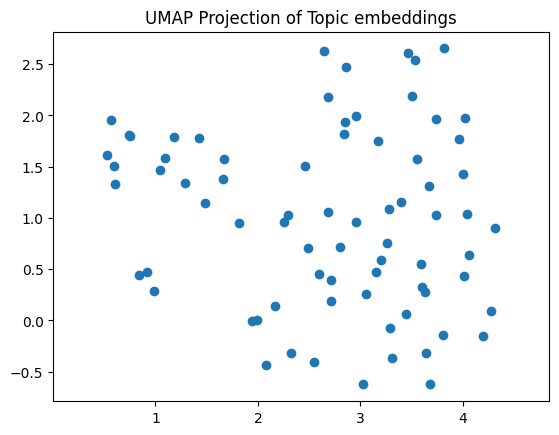

In [37]:
import matplotlib.pyplot as plt

plt.scatter(umap_embeddings[:, 0], umap_embeddings[:, 1])
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP Projection of Topic embeddings')

In [41]:
import sklearn.cluster as cluster
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score

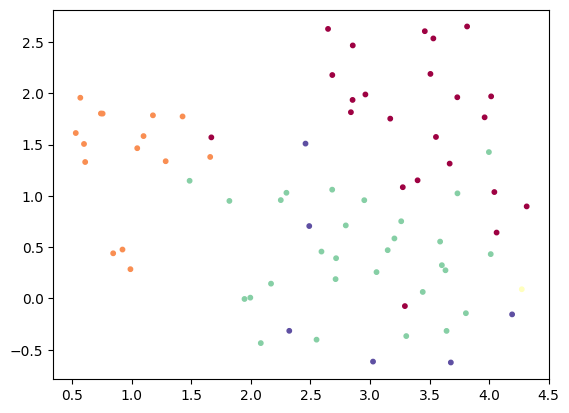

In [43]:
#try with 5 clusters:

kmeans_labels = cluster.KMeans(n_clusters = 5, random_state = 81).fit_predict(actual_output['embedding'].tolist())
plt.scatter(umap_embeddings[:, 0], umap_embeddings[:, 1], c = kmeans_labels, s = 10, cmap = 'Spectral' )

In [53]:
umap_df = pd.DataFrame(umap_embeddings, columns = ('x', 'y'))
umap_df['topic'] = actual_output['embedding'].tolist()
umap_df['cluster'] = kmeans_labels
umap_df['theme'] = actual_output['theme']
umap_df['id'] = actual_output['id']
umap_df['sub_id'] = actual_output['sub_id']

In [55]:
umap_df

,x,y,topic,cluster,theme,id,sub_id
0,2.796369,0.712437,"[-0.0237274169921875, 0.002529144287109375, 0....",3,Guidance,1,1
1,3.588372,0.554649,"[-0.020904541015625, -0.007350921630859375, 0....",3,Consultation,1,2
2,3.148265,0.470957,"[-0.02001953125, -0.006420135498046875, 0.0337...",3,Health care,1,3
3,1.819291,0.951362,"[-0.01556396484375, -0.0217132568359375, 0.006...",3,GPAI,1,4
4,0.567753,1.957722,"[-0.0099639892578125, -0.01346588134765625, 0....",1,High-risk AI applications,1,5
...,...,...,...,...,...,...,...
69,2.321975,-0.315667,"[-0.012054443359375, 0.0012674331665039062, 0....",4,harm mitigation,4,15
70,1.426104,1.775149,"[-0.019989013671875, -0.00525665283203125, 0.0...",1,AI purposes,4,16
71,2.250739,0.959325,"[-0.01233673095703125, -0.01306915283203125, 0...",3,DP-REG,4,17
72,2.082871,-0.435439,"[-0.0220947265625, 0.0095977783203125, 0.02505...",3,online safety,4,18
